# Four-stock SDE-GAN: data inspection and benchmark comparison

Inspect the four-stock dataset prepared from `Data/processed/log_returns_interpolated.csv` and compare:
- **Unconditional models:** Fixed `HistoricalSimulation` and the stabilized, mean-anchored `SDE-GAN` (per-seed + across-seed spread).
- **Conditional rolling models:** Rolling 252-session `HistoricalSimulation` and zero-shot `TSFMForecastBenchmark` (`thuml/sundial-base-128m` sample paths and `mistralai/Timestral-28M` 21-quantile forecasts).

Before running this notebook, run from the repository root:
```sh
uv run python experiments/4stocks/scripts/prepare_data.py
uv run python experiments/4stocks/scripts/train.py 0 1 2
uv run --extra tsfm python experiments/4stocks/scripts/run_tsfm.py --forecaster sundial
uv run --extra tsfm python experiments/4stocks/scripts/run_tsfm.py --forecaster timestral
```

In [1]:
from pathlib import Path
import json
import os
import sys

os.environ.setdefault('JAX_PLATFORMS', 'cpu')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'benchmarks/historical.py').is_file())
EXP_DIR = ROOT / 'experiments/4stocks'
DATA_DIR = EXP_DIR / 'data'
RUNS_DIR = EXP_DIR / 'results/sde_gan'
for p in (ROOT, EXP_DIR / 'model', EXP_DIR / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from benchmarks.historical import HistoricalSimulation, HistoricalSimulationConfig
from evaluate import (
    CONFIDENCE_LEVELS, ROLLING_LOOKBACK_SESSIONS, SUNDIAL_RELEASE_DATE,
    TSFM_FORECASTERS, TSFM_STYLES,
    acf, assert_compatible_preprocessing, load_observed, load_tsfm_forecasts, risk_rows, score_backtest_frame, terminal_returns,
)
from sde_gan import SDEGAN

SEEDS = (0, 1, 2)
N_PATHS = 10_000
SAMPLE_SEED = 100
CHECKPOINT = 'selected'  # 'selected' (lowest val MMD) or e.g. 'step_2000'
ROLLING_LOOKBACK = ROLLING_LOOKBACK_SESSIONS
EVALUATE_TEST = False    # Keep False until the baseline protocol is frozen.

meta = json.loads((DATA_DIR / 'preprocessing.json').read_text())
STOCKS = meta['stock_order']
MU = np.asarray(meta['training_mean'], dtype=np.float64)
STD = np.asarray(meta['training_std'], dtype=np.float64)
dates = pd.read_csv(DATA_DIR / 'window_dates.csv', parse_dates=['start_date', 'end_date'])

print('Source:', meta['source_file'])
print('Stocks:', STOCKS)
pd.DataFrame(meta['splits']).T

Source: Data/eligible/price_histories.csv
Stocks: ['KONGSBERG GRUPPEN', 'FRONTLINE', 'WILH, WILHELMSEN A', 'TOMRA SYSTEMS']


,source,first_date,last_date,rows,candidates,retained,rejected
train,train_returns.csv,2016-09-09,2023-09-05,1756,1737,1737,0
validation,validation_returns.csv,2023-09-06,2025-03-05,376,357,357,0
test,test_returns.csv,2025-03-06,2026-09-08,377,358,358,0


## 1. Observed splits and historical simulation benchmarks (fixed & rolling)

In [2]:
eval_splits = ('validation', 'test') if EVALUATE_TEST else ('validation',)
frames, observed = {}, {}
for split in ('train', *eval_splits):
    frames[split], observed[split] = load_observed(split, STOCKS, dates)

hist_common = dict(
    assets=tuple(STOCKS),
    weights={s: 1.0 / len(STOCKS) for s in STOCKS},
    return_type='simple',
    horizon_sessions=meta['window_length'],
    rebalance='daily',
    confidence_levels=CONFIDENCE_LEVELS,
    min_scenarios=100,
)
historical_fixed = HistoricalSimulation(
    HistoricalSimulationConfig(**hist_common, estimation='fixed')
).fit(frames['train'])
hist_summary = historical_fixed.summarize()
np.testing.assert_allclose(hist_summary.scenarios.portfolio_return,
                           terminal_returns(observed['train']), rtol=0, atol=1e-14)

rolling_forecasts = {}
for split in eval_splits:
    causal_history = (frames['train'] if split == 'validation'
                      else pd.concat([frames['train'], frames['validation']], ignore_index=True))
    rolling_forecasts[split] = HistoricalSimulation(HistoricalSimulationConfig(
        **hist_common, estimation='rolling', lookback_sessions=ROLLING_LOOKBACK,
    )).fit(causal_history).backtest(frames[split]).forecasts

split_stats = []
for split in ('train', *eval_splits):
    port = terminal_returns(observed[split])
    loss = -port
    split_stats.append({
        'split': split, 'windows': len(port),
        'port_mean_pct': 100 * port.mean(), 'port_std_pct': 100 * port.std(ddof=1),
        'loss_q95_pct': 100 * np.quantile(loss, 0.95), 'loss_q99_pct': 100 * np.quantile(loss, 0.99),
    })
display(pd.DataFrame(split_stats).set_index('split').round(3))
display(hist_summary.risk)

,windows,port_mean_pct,port_std_pct,loss_q95_pct,loss_q99_pct
split,,,,,
train,1737,1.960,5.473,6.569,11.184
validation,357,3.152,5.484,5.227,8.757


,method,confidence,horizon_sessions,rebalance,var,es,tail_mass_observations,small_tail_sample,overlapping_scenarios,history_start,history_end,n_history_sessions,n_candidate_blocks,n_excluded_blocks,n_scenarios,portfolio_mean_return,portfolio_std_return
0,historical_simulation,0.95,20,daily,0.066016,0.098111,86.85,False,True,2016-09-09,2023-09-05,1756,1737,0,1737,0.019598,0.054728
1,historical_simulation,0.99,20,daily,0.112023,0.154597,17.37,True,True,2016-09-09,2023-09-05,1756,1737,0,1737,0.019598,0.054728


## 2. Load saved SDE-GAN seeds and TSFM forecasts

Loaded TSFM (sundial) validation forecasts: 714 rows
Loaded TSFM (timestral) validation forecasts: 714 rows


,selected_step,validation_mmd2,train_mean_error
seed,,,
0,1900,0.002351,0.036110
1,1000,0.004560,0.028708
2,700,0.002294,0.016313


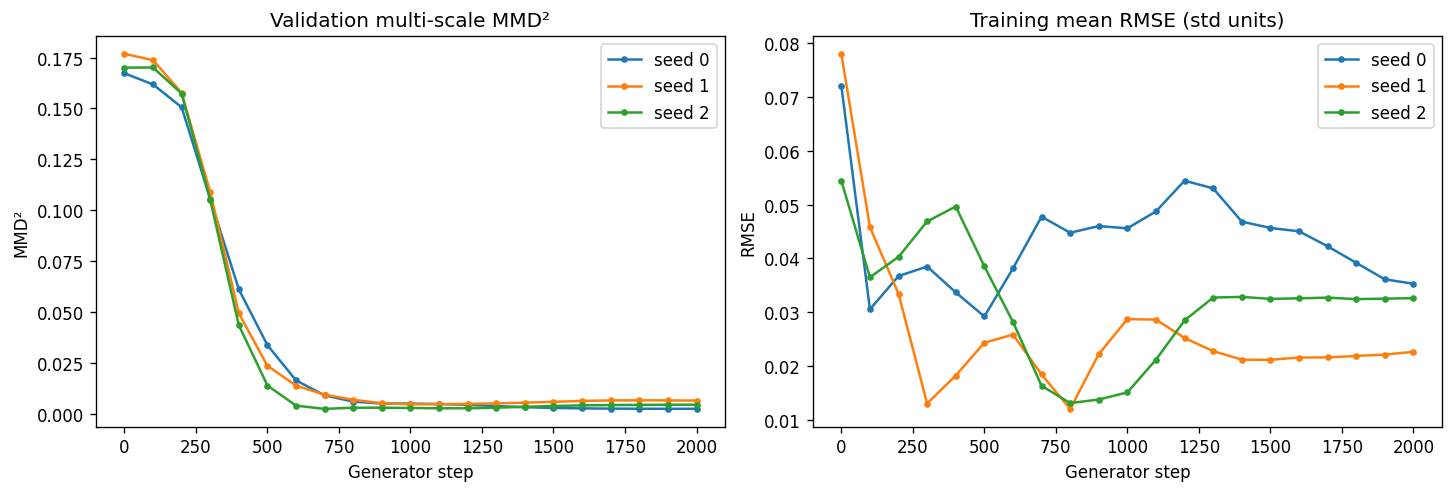

In [3]:
generated, histories, inventory = {}, {}, []
for seed in SEEDS:
    run_dir = RUNS_DIR / f'seed_{seed}'
    if not (run_dir / 'completion.json').is_file():
        print(f'Skipping missing SDE-GAN seed {seed} ({run_dir})')
        continue
    load_dir = run_dir if CHECKPOINT == 'selected' else run_dir / 'checkpoints' / CHECKPOINT
    assert_compatible_preprocessing(json.loads((load_dir / 'preprocessing.json').read_text()), meta, f'SDE-GAN seed {seed}')
    model = SDEGAN.load(load_dir)
    standardized = model.sample(N_PATHS, SAMPLE_SEED)
    generated[seed] = np.expm1(standardized.astype(np.float64) * STD + MU)
    histories[seed] = pd.read_csv(run_dir / 'history.csv')
    inventory.append({
        'seed': seed, 'selected_step': model.run_metadata['selected_step'],
        'validation_mmd2': model.run_metadata['validation_score'],
        'train_mean_error': model.run_metadata.get('train_mean_error'),
    })

tsfm_forecasts = {name: {} for name in TSFM_FORECASTERS}
for forecaster in TSFM_FORECASTERS:
    for split in eval_splits:
        loaded = load_tsfm_forecasts(forecaster, split, meta)
        if loaded is not None:
            tsfm_forecasts[forecaster][split] = loaded
            print(f'Loaded TSFM ({forecaster}) {split} forecasts: {len(loaded)} rows')
        else:
            print(
                f'No saved TSFM ({forecaster}) {split} forecasts yet. '
                f'Run: uv run --extra tsfm python experiments/4stocks/scripts/run_tsfm.py --forecaster {forecaster}'
            )

if inventory:
    display(pd.DataFrame(inventory).set_index('seed').round(6))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for seed, h in histories.items():
        val = h.dropna(subset=['validation_mmd2'])
        axes[0].plot(val['step'], val['validation_mmd2'], marker='.', label=f'seed {seed}')
        if 'train_mean_error' in val:
            axes[1].plot(val['step'], val['train_mean_error'], marker='.', label=f'seed {seed}')
    axes[0].set(title='Validation multi-scale MMD²', xlabel='Generator step', ylabel='MMD²')
    axes[1].set(title='Training mean RMSE (std units)', xlabel='Generator step', ylabel='RMSE')
    for ax in axes:
        ax.legend()
    plt.show()
else:
    print('No completed SDE-GAN runs found yet. Run: uv run python experiments/4stocks/scripts/train.py 0 1 2')

## 3. Unified portfolio risk comparison: Fixed HS, Rolling HS, TSFMs (Sundial & Timestral-28M), and SDE-GAN

**Methodological notes:**
- **Unconditional vs. conditional:** Fixed HS and SDE-GAN output one fixed VaR/ES distribution; Rolling HS (252d), Sundial (252d context, 1,000 sample paths), and Timestral-28M (252d context, 21 marginal quantiles) adapt their VaR at every forecast origin.
- **Quantile-head ES (`Timestral-28M`):** Timestral outputs 21 fixed quantiles (`0.01, 0.05, ..., 0.99`), giving exact 95% and 99% VaR in `log_price` mode with zero sampling noise, but no quantiles below `0.01`, so `es_pct` is `NaN`.
- **Release-date provenance:** `thuml/sundial-base-128m` was released in **February 2025** (`arXiv:2502.00816`; test split is post-release). `mistralai/Timestral-28M` was released in **October 2026** (`v1.0.0`).

=== VALIDATION RISK SCORES ===


targets  ...  quantile_loss_pct
model                  seed confidence           ...                   
historical_fixed       -1   0.95            357  ...             0.5334
                            0.99            357  ...             0.1435
historical_rolling_252 -1   0.95            357  ...             0.5753
                            0.99            357  ...             0.1905
tsfm_sundial           -1   0.95            357  ...             0.6615
                            0.99            357  ...             0.1757
tsfm_timestral         -1   0.95            357  ...             0.6328
                            0.99            357  ...             0.1876
sde_gan                 0   0.95            357  ...             0.5538
                            0.99            357  ...             0.1406
                        1   0.95            357  ...             0.5232
                            0.99            357  ...             0.1253
                        2   0.95            357  ...             0.6091
                            0.99            357  ...             0.1585

[14 rows x 7 columns]

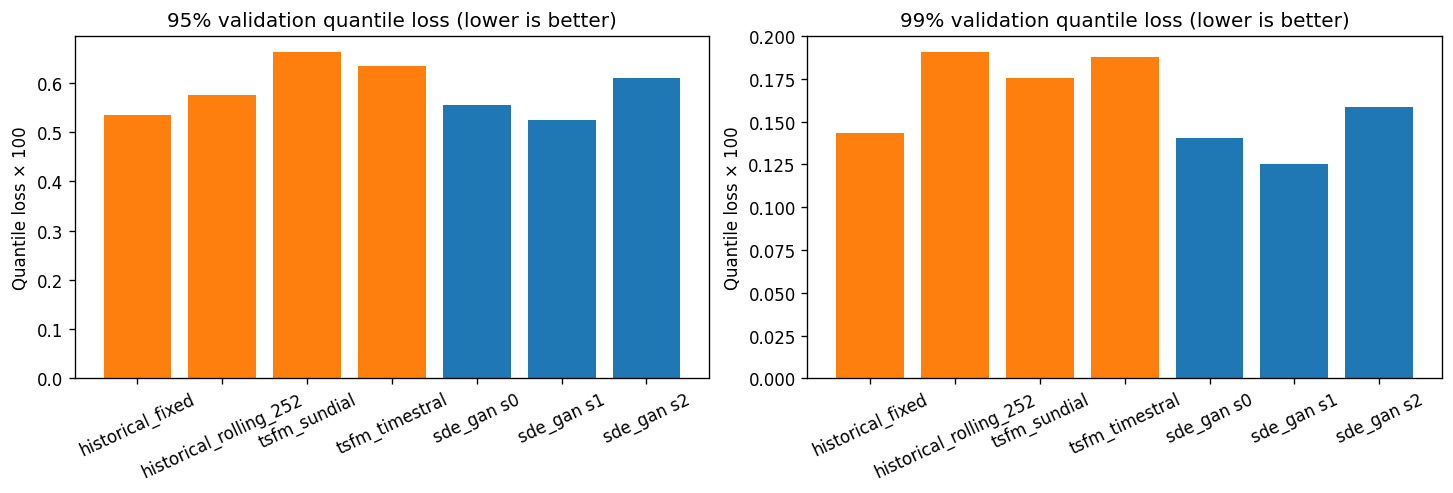

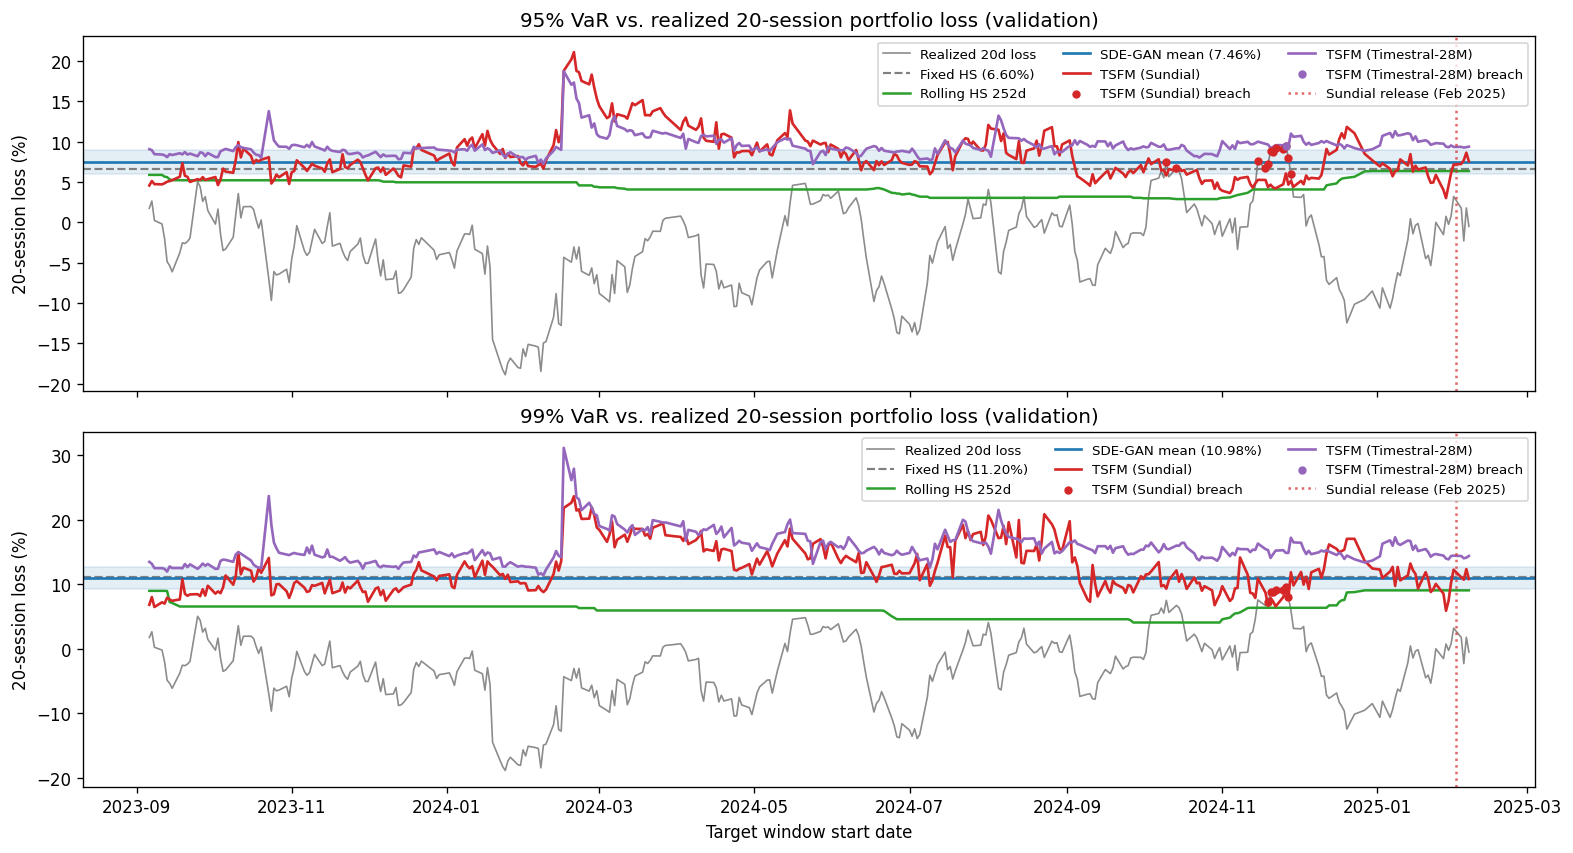

In [4]:
for split in eval_splits:
    realized = -terminal_returns(observed[split])
    rows = [{**r, 'model': 'historical_fixed', 'seed': -1} for r in risk_rows(observed['train'], realized)]
    rows.extend({**r, 'model': f'historical_rolling_{ROLLING_LOOKBACK}', 'seed': -1}
                for r in score_backtest_frame(rolling_forecasts[split]))
    for forecaster in TSFM_FORECASTERS:
        if split in tsfm_forecasts[forecaster]:
            rows.extend({**r, 'model': f'tsfm_{forecaster}', 'seed': -1}
                        for r in score_backtest_frame(tsfm_forecasts[forecaster][split]))
    for seed, paths in generated.items():
        rows.extend({**r, 'model': 'sde_gan', 'seed': seed} for r in risk_rows(paths, realized))
    df = pd.DataFrame(rows)
    print(f'=== {split.upper()} RISK SCORES ===')
    display(df.set_index(['model', 'seed', 'confidence']).round(4))

    # Bar chart of quantile loss across all available models
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for confidence, ax in zip(CONFIDENCE_LEVELS, axes):
        sub = df.loc[df.confidence.eq(confidence)]
        bench = sub.loc[~sub.model.eq('sde_gan')]
        gan = sub.loc[sub.model.eq('sde_gan')]
        labels = list(bench.model) + [f'sde_gan s{s}' for s in gan.seed]
        vals = list(bench.quantile_loss_pct) + list(gan.quantile_loss_pct)
        colors = ['C1'] * len(bench) + ['C0'] * len(gan)
        ax.bar(labels, vals, color=colors)
        ax.set(title=f'{confidence:.0%} {split} quantile loss (lower is better)', ylabel='Quantile loss × 100')
        ax.tick_params(axis='x', rotation=25)
    plt.show()

    # Time-series plot: realized 20-session loss vs time-varying and fixed VaR forecasts
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
    r_bt = rolling_forecasts[split]
    for confidence, ax in zip(CONFIDENCE_LEVELS, axes):
        rsub = r_bt.loc[r_bt.confidence.eq(confidence)].sort_values('target_start')
        t = rsub['target_start']
        ax.plot(t, 100.0 * rsub['realized_loss'], color='black', alpha=0.45, linewidth=1.0, label='Realized 20d loss')
        fixed_var = df.loc[df.model.eq('historical_fixed') & df.confidence.eq(confidence), 'var_pct'].iloc[0]
        ax.axhline(fixed_var, color='grey', linestyle='--', linewidth=1.3, label=f'Fixed HS ({fixed_var:.2f}%)')
        ax.plot(t, 100.0 * rsub['var'], color='C2', linewidth=1.5, label=f'Rolling HS {ROLLING_LOOKBACK}d')
        if generated:
            gvars = df.loc[df.model.eq('sde_gan') & df.confidence.eq(confidence), 'var_pct']
            ax.axhline(gvars.mean(), color='C0', linewidth=1.6, label=f'SDE-GAN mean ({gvars.mean():.2f}%)')
            ax.axhspan(gvars.min(), gvars.max(), color='C0', alpha=0.12)
        for forecaster in TSFM_FORECASTERS:
            if split not in tsfm_forecasts[forecaster]:
                continue
            color, label = TSFM_STYLES[forecaster]
            tsub = tsfm_forecasts[forecaster][split].loc[
                tsfm_forecasts[forecaster][split].confidence.eq(confidence)
            ].sort_values('target_start')
            ax.plot(tsub['target_start'], 100.0 * tsub['var'], color=color, linewidth=1.6, label=label)
            breach_pts = tsub.loc[tsub['breach'].fillna(False)]
            ax.scatter(breach_pts['target_start'], 100.0 * breach_pts['realized_loss'],
                       color=color, s=16, zorder=5, label=f'{label} breach')
        if t.min() <= SUNDIAL_RELEASE_DATE <= t.max():
            ax.axvline(SUNDIAL_RELEASE_DATE, color='C3', linestyle=':', alpha=0.7, label='Sundial release (Feb 2025)')
        ax.set(title=f'{confidence:.0%} VaR vs. realized 20-session portfolio loss ({split})', ylabel='20-session loss (%)')
        ax.legend(fontsize=8, ncol=3, loc='upper right')
    axes[-1].set_xlabel('Target window start date')
    plt.show()

## 4. Forecast distributions on 5 random validation windows (Sundial vs. Timestral-28M vs. SDE-GAN)

Pick 5 random validation origins (`WINDOW_PLOT_SEED`) and compare **TSFM Sundial** (1,000 simulated paths), **TSFM Timestral-28M** (21-quantile fan: 1%–99%, 5%–95%, 25%–75% bands + median), and **SDE-GAN** (seed 0, 10,000 unconditional paths) alongside the preceding 20-session context and the realized 20-session trajectory (bold black). All three panels share the same y-axis per window. Sampled Sundial trajectories are cached in `results/tsfm/sample_window_paths.npz` and Timestral quantile fans in `results/tsfm/timestral/sample_window_quantiles.npz`.

Loaded cached Sundial paths for windows [31, 154, 156, 232, 273] from sample_window_paths.npz
Running Timestral-28M quantile forecast for 5 random validation windows...
Cached Timestral quantile fans to /Users/pasha/Desktop/master/master_thesis/experiments/4stocks/results/tsfm/timestral/sample_window_quantiles.npz


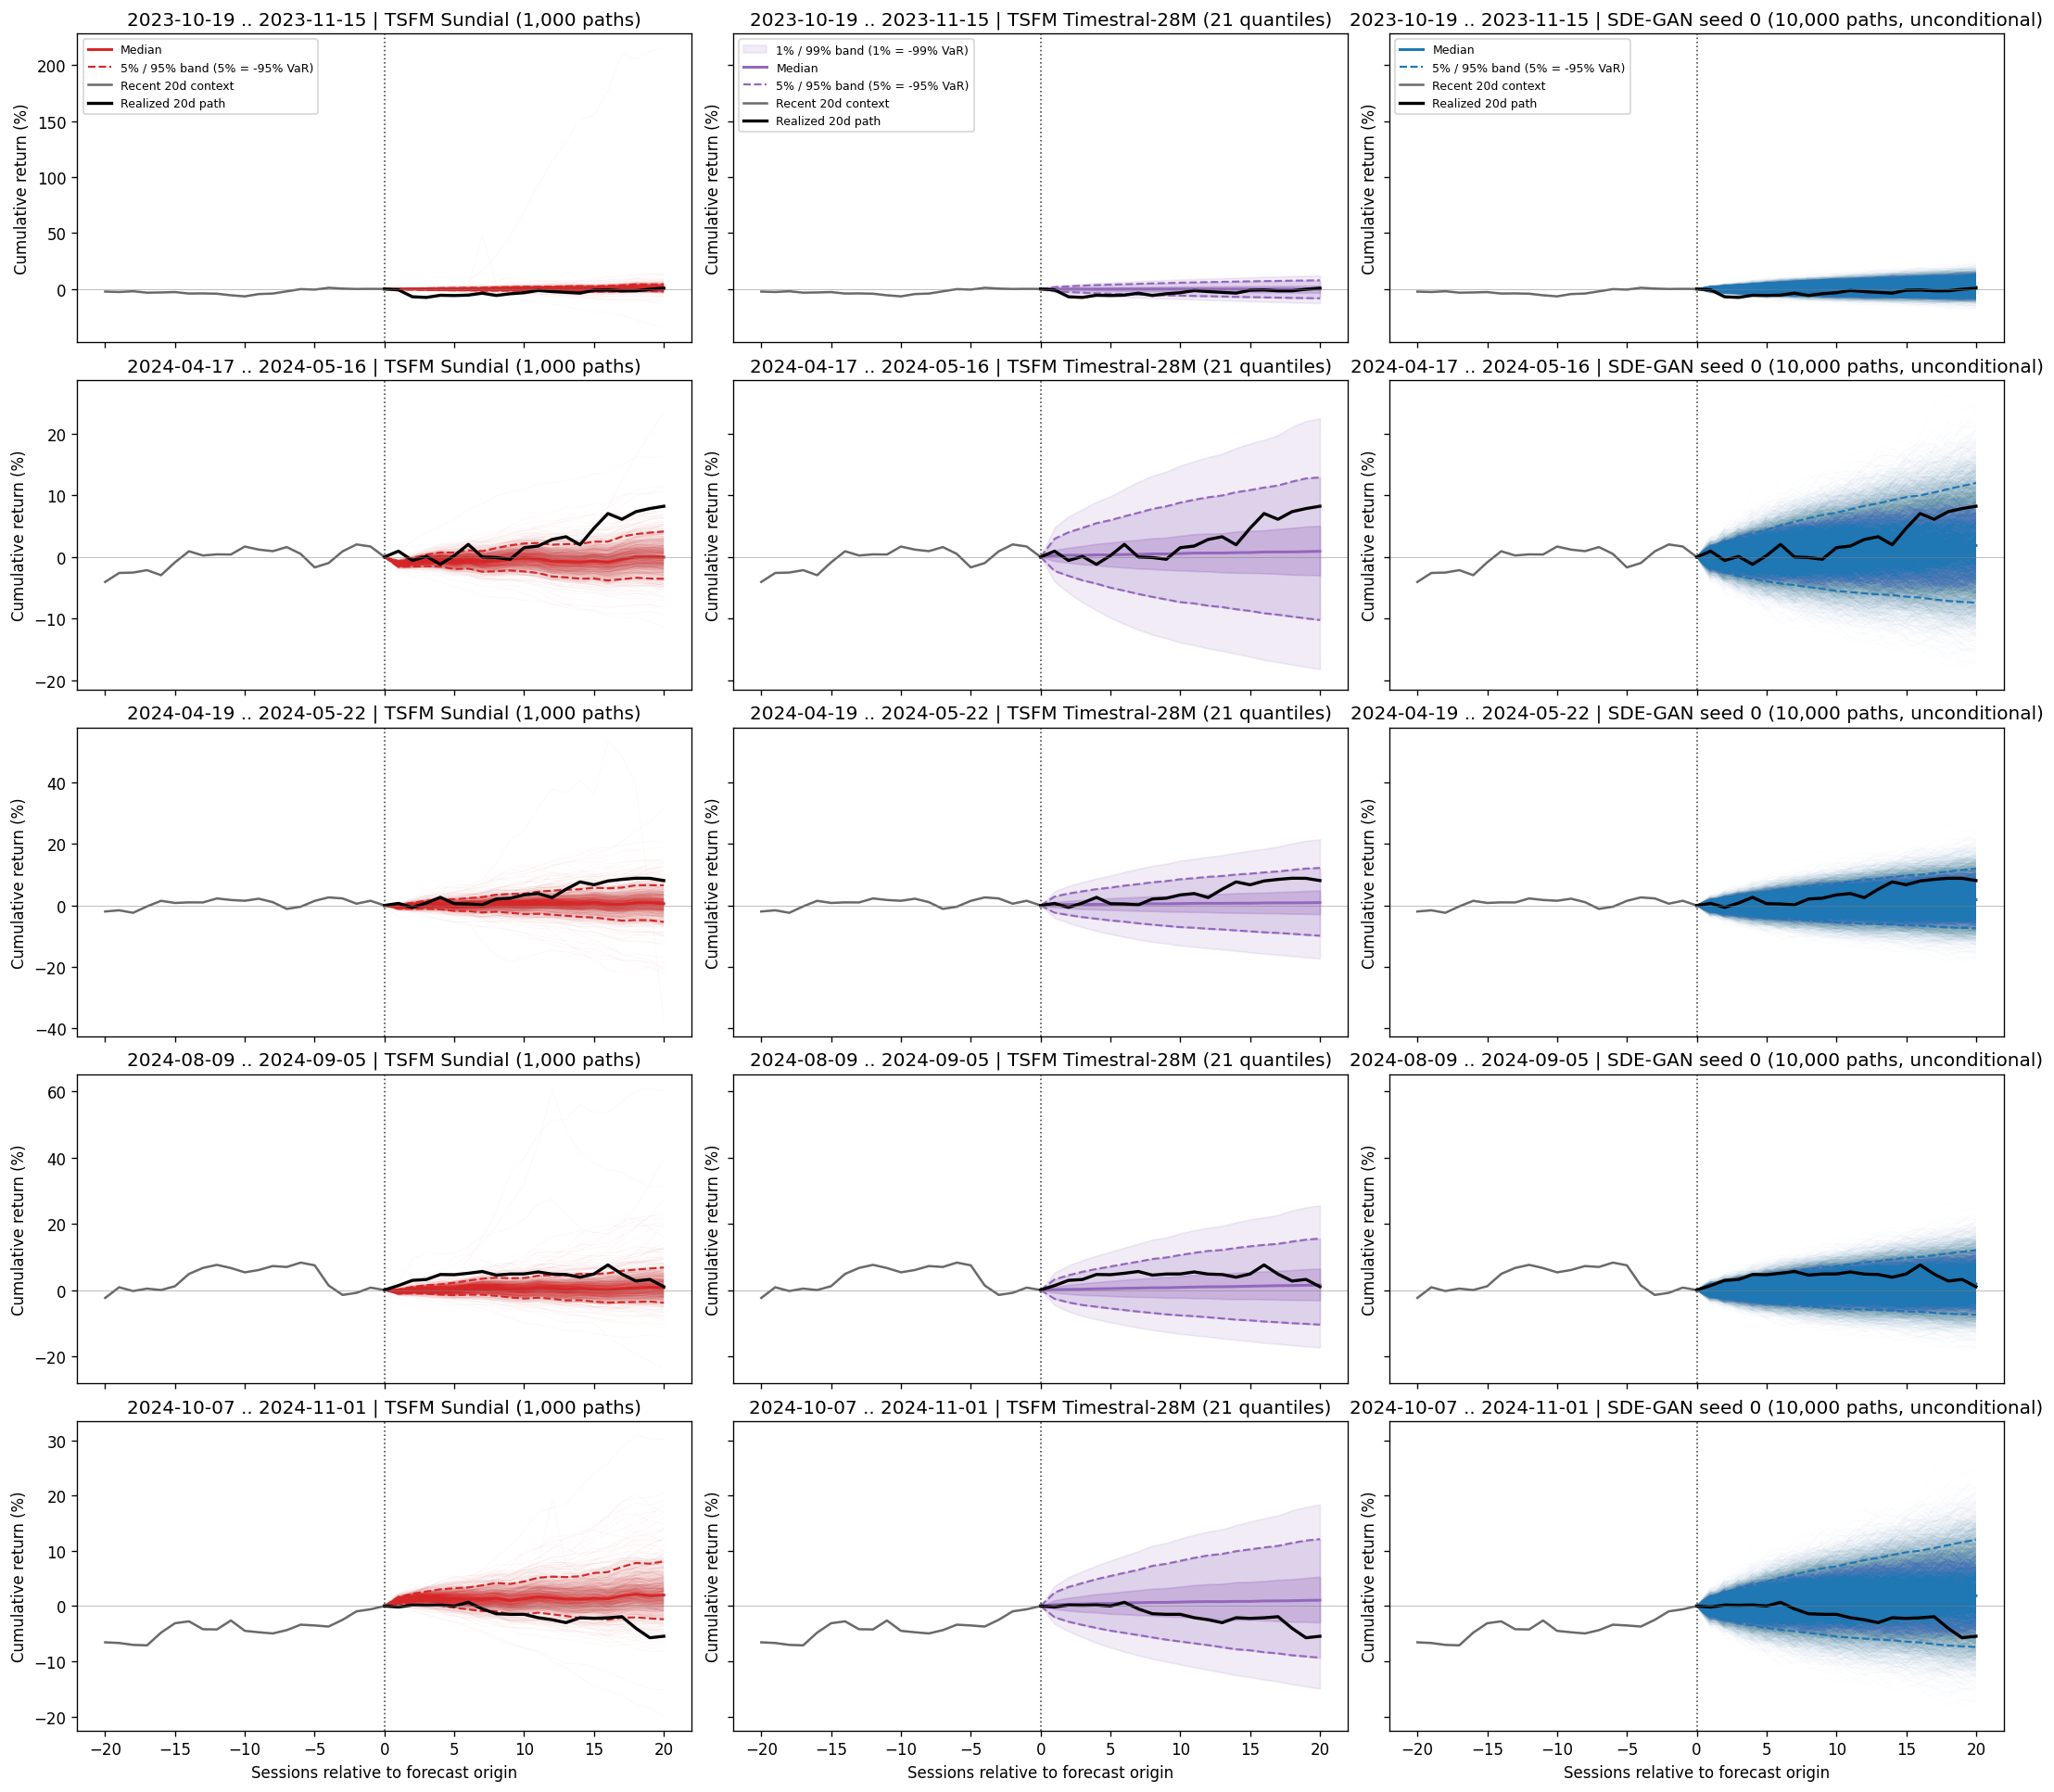

In [5]:
from matplotlib.collections import LineCollection
from benchmarks.tsfm import TSFMConfig, TSFMForecastBenchmark

N_RANDOM_WINDOWS = 5
WINDOW_PLOT_SEED = 42
CONTEXT_PLOT_SESSIONS = 20
SDE_GAN_PLOT_SEED = 0
TSFM_NUM_SAMPLES = 1000

val_dates = dates.loc[dates.split.eq('validation')].sort_values('window_index').reset_index(drop=True)
rng = np.random.default_rng(WINDOW_PLOT_SEED)
chosen_indices = np.sort(rng.choice(len(val_dates), size=N_RANDOM_WINDOWS, replace=False))

combined_df = pd.concat([frames['train'], frames['validation']], ignore_index=True)
combined_indexed = combined_df.set_index('Date').loc[:, STOCKS]
n_train_rows = len(frames['train'])
weights_vec = np.full(len(STOCKS), 1.0 / len(STOCKS))

# Load or sample all 1,000 Sundial 20-session trajectories for the 5 chosen origins
cache_path = EXP_DIR / 'results/tsfm/sample_window_paths.npz'
tsfm_paths_pct = None
if cache_path.is_file():
    cached = np.load(cache_path, allow_pickle=False)
    if (np.array_equal(cached['window_indices'], chosen_indices)
            and int(cached['num_samples']) == TSFM_NUM_SAMPLES
            and 'revin' in cached and bool(cached['revin']) is False
            and str(cached['source_sha256']) == meta['source_sha256']):
        tsfm_paths_pct = cached['paths_pct']
        print(f'Loaded cached Sundial paths for windows {chosen_indices.tolist()} from {cache_path.name}')

if tsfm_paths_pct is None:
    print(f'Sampling {TSFM_NUM_SAMPLES} Sundial paths for {N_RANDOM_WINDOWS} random validation windows...')
    tsfm_cfg = TSFMConfig(
        assets=tuple(STOCKS),
        weights={s: 1.0 / len(STOCKS) for s in STOCKS},
        return_type='simple',
        target='log_price',
        horizon_sessions=meta['window_length'],
        rebalance='daily',
        context_sessions=252,
        num_samples=TSFM_NUM_SAMPLES,
        sample_chunk_size=250,
        revin=False,
        seed=0,
        device='cpu',
    )
    tsfm_bench = TSFMForecastBenchmark(tsfm_cfg).fit(frames['train'])
    contexts = []
    for w_idx in chosen_indices:
        pos = n_train_rows + int(w_idx)
        ctx, _, status = tsfm_bench._build_context(combined_indexed.iloc[:pos])
        assert status == 'ok' and ctx is not None
        contexts.append(ctx)
    raw_log_paths = tsfm_bench._forecaster.sample(
        np.stack(contexts, axis=0), horizon=meta['window_length'],
        num_samples=TSFM_NUM_SAMPLES, seed=WINDOW_PLOT_SEED,
    )
    zero_col = np.zeros((N_RANDOM_WINDOWS, TSFM_NUM_SAMPLES, 1), dtype=np.float64)
    tsfm_paths_pct = 100.0 * np.expm1(np.concatenate([zero_col, raw_log_paths], axis=2))
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        cache_path, window_indices=chosen_indices, num_samples=TSFM_NUM_SAMPLES,
        revin=False, source_sha256=meta['source_sha256'], paths_pct=tsfm_paths_pct.astype(np.float32),
    )
    print(f'Cached Sundial sample paths to {cache_path}')

# Load or predict 21-quantile Timestral-28M fans for the same 5 origins
tim_cache_path = EXP_DIR / 'results/tsfm/timestral/sample_window_quantiles.npz'
tim_quantiles_pct, tim_levels = None, None
if tim_cache_path.is_file():
    cached = np.load(tim_cache_path, allow_pickle=False)
    if (np.array_equal(cached['window_indices'], chosen_indices)
            and str(cached['source_sha256']) == meta['source_sha256']):
        tim_quantiles_pct = cached['quantiles_pct']
        tim_levels = tuple(float(x) for x in cached['quantile_levels'])
        print(f'Loaded cached Timestral quantiles for windows {chosen_indices.tolist()} from {tim_cache_path.name}')

if tim_quantiles_pct is None:
    print(f'Running Timestral-28M quantile forecast for {N_RANDOM_WINDOWS} random validation windows...')
    tim_cfg = TSFMConfig(
        assets=tuple(STOCKS),
        weights={s: 1.0 / len(STOCKS) for s in STOCKS},
        return_type='simple',
        target='log_price',
        horizon_sessions=meta['window_length'],
        rebalance='daily',
        context_sessions=252,
        forecaster='timestral',
        device='cpu',
    )
    tim_bench = TSFMForecastBenchmark(tim_cfg).fit(frames['train'])
    contexts = []
    for w_idx in chosen_indices:
        pos = n_train_rows + int(w_idx)
        ctx, _, status = tim_bench._build_context(combined_indexed.iloc[:pos])
        assert status == 'ok' and ctx is not None
        contexts.append(ctx)
    raw_log_q, tim_levels = tim_bench._forecaster.predict_quantiles(
        np.stack(contexts, axis=0), horizon=meta['window_length'],
    )
    zero_col = np.zeros((N_RANDOM_WINDOWS, len(tim_levels), 1), dtype=np.float64)
    tim_quantiles_pct = 100.0 * np.expm1(np.concatenate([zero_col, raw_log_q], axis=2))
    tim_cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        tim_cache_path, window_indices=chosen_indices,
        quantile_levels=np.asarray(tim_levels, dtype=np.float64),
        source_sha256=meta['source_sha256'],
        quantiles_pct=tim_quantiles_pct.astype(np.float32),
    )
    print(f'Cached Timestral quantile fans to {tim_cache_path}')

# Build all SDE-GAN cumulative portfolio return paths (t = 0..20)
gan_paths_pct = None
if SDE_GAN_PLOT_SEED in generated:
    gan_daily = generated[SDE_GAN_PLOT_SEED].mean(axis=2)
    gan_wealth = np.concatenate([np.ones((len(gan_daily), 1)), np.cumprod(1.0 + gan_daily, axis=1)], axis=1)
    gan_paths_pct = 100.0 * (gan_wealth - 1.0)


def plot_path_fan(ax, t_ctx, ctx_pct, t_fut, realized_pct, paths_pct, color, alpha, title):
    segs = np.stack([np.broadcast_to(t_fut, paths_pct.shape), paths_pct], axis=-1)
    ax.add_collection(LineCollection(segs, colors=color, linewidths=0.45, alpha=alpha, rasterized=True))
    q05, q50, q95 = np.quantile(paths_pct, (0.05, 0.50, 0.95), axis=0)
    ax.plot(t_fut, q50, color=color, linewidth=1.8, label='Median')
    ax.plot(t_fut, q05, color=color, linestyle='--', linewidth=1.3, label='5% / 95% band (5% = -95% VaR)')
    ax.plot(t_fut, q95, color=color, linestyle='--', linewidth=1.3)
    ax.plot(t_ctx, ctx_pct, color='dimgray', linewidth=1.5, label='Recent 20d context')
    ax.plot(t_fut, realized_pct, color='black', linewidth=2.0, label='Realized 20d path')
    ax.axvline(0, color='black', linestyle=':', linewidth=1.0, alpha=0.7)
    ax.axhline(0, color='grey', linewidth=0.6, alpha=0.5)
    ax.set(title=title, ylabel='Cumulative return (%)')
    ax.autoscale_view()


def plot_quantile_fan(ax, t_ctx, ctx_pct, t_fut, realized_pct, q_pct, q_levels, color, title):
    def at(level: float) -> np.ndarray:
        idx = min(range(len(q_levels)), key=lambda i: abs(q_levels[i] - level))
        return q_pct[idx]

    ax.fill_between(t_fut, at(0.01), at(0.99), color=color, alpha=0.12, label='1% / 99% band (1% = -99% VaR)')
    ax.fill_between(t_fut, at(0.05), at(0.95), color=color, alpha=0.20)
    ax.fill_between(t_fut, at(0.25), at(0.75), color=color, alpha=0.28)
    ax.plot(t_fut, at(0.50), color=color, linewidth=1.8, label='Median')
    ax.plot(t_fut, at(0.05), color=color, linestyle='--', linewidth=1.3, label='5% / 95% band (5% = -95% VaR)')
    ax.plot(t_fut, at(0.95), color=color, linestyle='--', linewidth=1.3)
    ax.plot(t_ctx, ctx_pct, color='dimgray', linewidth=1.5, label='Recent 20d context')
    ax.plot(t_fut, realized_pct, color='black', linewidth=2.0, label='Realized 20d path')
    ax.axvline(0, color='black', linestyle=':', linewidth=1.0, alpha=0.7)
    ax.axhline(0, color='grey', linewidth=0.6, alpha=0.5)
    ax.set(title=title, ylabel='Cumulative return (%)')
    ax.autoscale_view()


t_ctx = np.arange(-CONTEXT_PLOT_SESSIONS, 1, dtype=np.float64)
t_fut = np.arange(0, meta['window_length'] + 1, dtype=np.float64)
fig, axes = plt.subplots(N_RANDOM_WINDOWS, 3, figsize=(18, 3.2 * N_RANDOM_WINDOWS),
                         sharex=True, sharey='row', constrained_layout=True)
for row_i, w_idx in enumerate(chosen_indices):
    pos = n_train_rows + int(w_idx)
    start_dt = val_dates.loc[int(w_idx), 'start_date'].strftime('%Y-%m-%d')
    end_dt = val_dates.loc[int(w_idx), 'end_date'].strftime('%Y-%m-%d')

    ctx_ret = combined_indexed.iloc[pos - CONTEXT_PLOT_SESSIONS : pos].to_numpy() @ weights_vec
    ctx_log = np.log1p(ctx_ret)
    ctx_pct = 100.0 * np.expm1(np.concatenate([-np.cumsum(ctx_log[::-1])[::-1], [0.0]]))
    fut_ret = observed['validation'][int(w_idx)].mean(axis=1)
    realized_pct = 100.0 * (np.concatenate([[1.0], np.cumprod(1.0 + fut_ret)]) - 1.0)

    plot_path_fan(
        axes[row_i, 0], t_ctx, ctx_pct, t_fut, realized_pct, tsfm_paths_pct[row_i],
        color='C3', alpha=0.04,
        title=f'{start_dt} .. {end_dt} | TSFM Sundial ({len(tsfm_paths_pct[row_i]):,} paths)',
    )
    plot_quantile_fan(
        axes[row_i, 1], t_ctx, ctx_pct, t_fut, realized_pct, tim_quantiles_pct[row_i], tim_levels,
        color='C4',
        title=f'{start_dt} .. {end_dt} | TSFM Timestral-28M ({len(tim_levels)} quantiles)',
    )
    if gan_paths_pct is not None:
        plot_path_fan(
            axes[row_i, 2], t_ctx, ctx_pct, t_fut, realized_pct, gan_paths_pct,
            color='C0', alpha=0.015,
            title=f'{start_dt} .. {end_dt} | SDE-GAN seed {SDE_GAN_PLOT_SEED} ({len(gan_paths_pct):,} paths, unconditional)',
        )
    if row_i == 0:
        for col_i in range(3):
            axes[row_i, col_i].legend(fontsize=7.5, loc='upper left')

for col_i in range(3):
    axes[-1, col_i].set_xlabel('Sessions relative to forecast origin')
plt.show()

## 5. Multivariate distribution faithfulness (Observed vs. SDE-GAN)

TSFM forecasts the 1D portfolio series directly, so cross-stock correlation and per-stock ACF diagnostics apply to the multivariate SDE-GAN versus observed data.

,port_mean_pct,port_std_pct,mean_rmse_std,vol_rmse_train,corr_rmse_train,signed_acf_rmse,abs_acf_rmse
seed,,,,,,,
0,2.0314,5.8956,0.0377,0.0637,0.0721,0.0830,0.1328
1,2.0188,5.0590,0.0215,0.0385,0.0774,0.0419,0.1539
2,1.4857,6.5540,0.0186,0.0982,0.1005,0.0381,0.1524


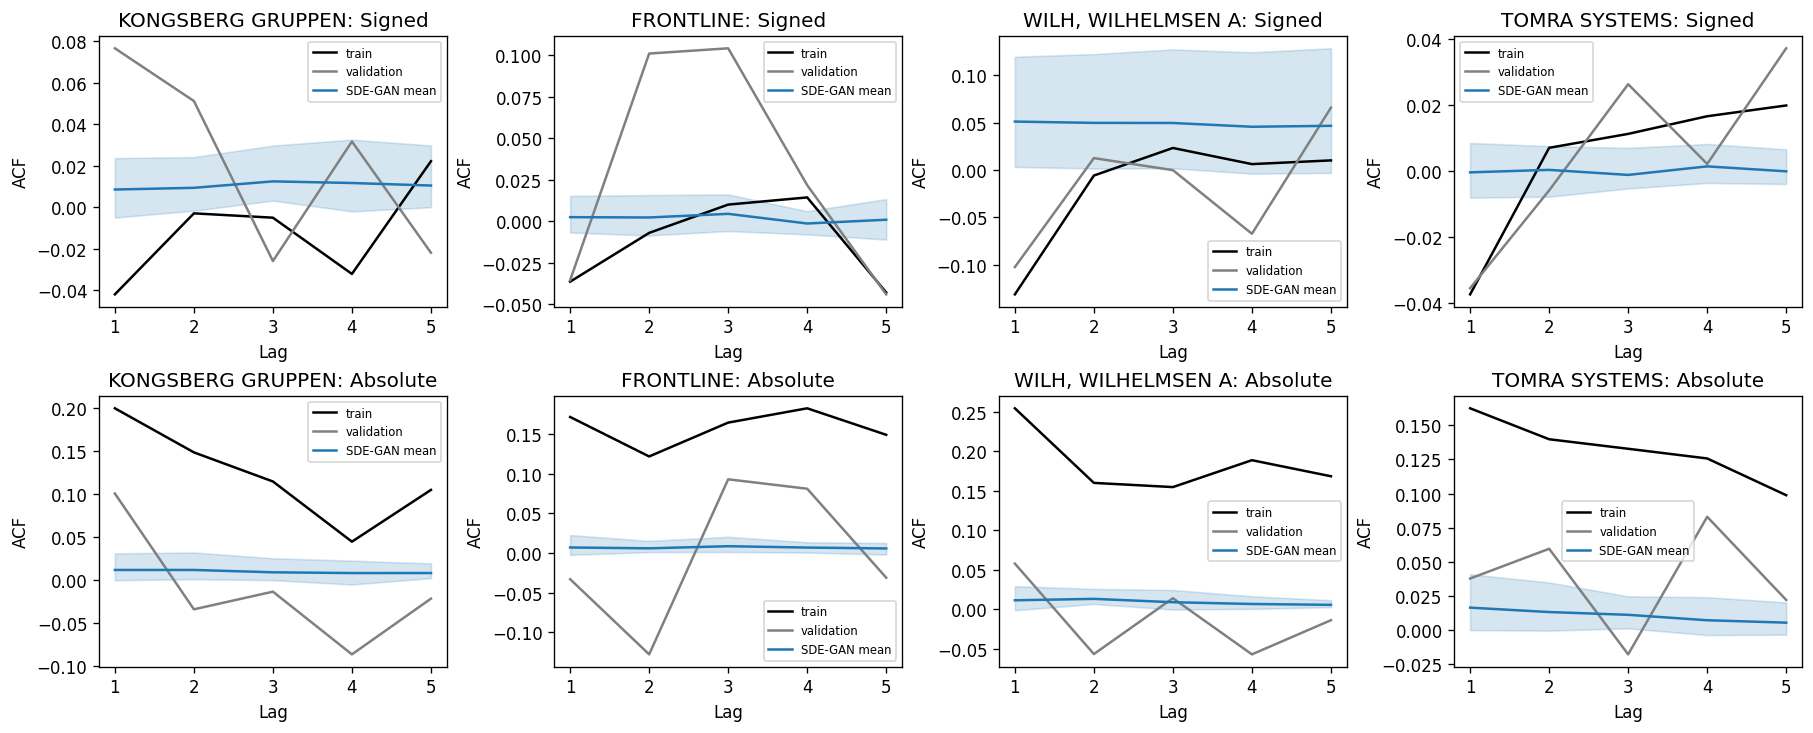

In [6]:
if generated:
    train_flat = observed['train'].reshape(-1, len(STOCKS))
    train_mean, train_std = train_flat.mean(0), train_flat.std(0, ddof=1)
    train_corr = np.corrcoef(train_flat.T)
    train_signed, train_abs = acf(observed['train']), acf(observed['train'], True)
    pairs = np.triu_indices(len(STOCKS), 1)

    dist_rows = []
    for seed, paths in generated.items():
        flat = paths.reshape(-1, len(STOCKS))
        port = terminal_returns(paths)
        dist_rows.append({
            'seed': seed,
            'port_mean_pct': 100 * port.mean(),
            'port_std_pct': 100 * port.std(ddof=1),
            'mean_rmse_std': np.sqrt(np.mean(((flat.mean(0) - train_mean) / train_std) ** 2)),
            'vol_rmse_train': np.sqrt(np.mean((flat.std(0, ddof=1) / train_std - 1) ** 2)),
            'corr_rmse_train': np.sqrt(np.mean((np.corrcoef(flat.T) - train_corr)[pairs] ** 2)),
            'signed_acf_rmse': np.sqrt(np.mean((acf(paths) - train_signed) ** 2)),
            'abs_acf_rmse': np.sqrt(np.mean((acf(paths, True) - train_abs) ** 2)),
        })
    display(pd.DataFrame(dist_rows).set_index('seed').round(4))

    fig, axes = plt.subplots(2, len(STOCKS), figsize=(15, 6), constrained_layout=True)
    for row_idx, (label, is_abs) in enumerate((('Signed', False), ('Absolute', True))):
        for j, stock in enumerate(STOCKS):
            ax = axes[row_idx, j]
            ax.plot(range(1, 6), acf(observed['train'], is_abs)[:, j], color='black', label='train')
            ax.plot(range(1, 6), acf(observed['validation'], is_abs)[:, j], color='grey', label='validation')
            curves = np.stack([acf(paths, is_abs)[:, j] for paths in generated.values()])
            ax.plot(range(1, 6), curves.mean(0), color='C0', label='SDE-GAN mean')
            ax.fill_between(range(1, 6), curves.min(0), curves.max(0), color='C0', alpha=0.18)
            ax.set(title=f'{stock}: {label}', xlabel='Lag', ylabel='ACF', xticks=range(1, 6))
            ax.legend(fontsize=7)
    plt.show()